# Módulo 4: Aprendizaje Automático (Machine Learning)
## Semana 2 - Clase 5: Taller Comparativo de Clasificadores

En la clase anterior utilizamos **Regresión Logística** para predecir categorías. Sin embargo, en la Inteligencia Artificial existe el teorema del *"No Free Lunch"* (No hay almuerzo gratis), que dicta que **ningún algoritmo es perfecto para todos los problemas**.

Hoy realizaremos un **Taller Comparativo** paso a paso. Usaremos un dataset químico de **Vinos** y enfrentaremos a 3 algoritmos con filosofías radicalmente distintas para ver cómo "piensan" y cómo toman decisiones:

1. **k-Nearest Neighbors (k-NN):** Filosofía basada en Similitud y Distancia (Geometría).
2. **Árboles de Decisión:** Filosofía basada en Reglas Lógicas (If-Then).
3. **Naive Bayes:** Filosofía basada en Probabilidad Teórica.

---
## **Paso 1: Extracción y Exploración de Datos**

Utilizaremos el famoso dataset *Wine Quality* incluido en `scikit-learn`. El objetivo es predecir de qué **cultivo (Clase 0, 1 o 2)** proviene un vino basándonos en sus componentes químicos.

### Diccionario de Datos (Traducción al Español)
Dado que las bases de datos originales están en inglés, aquí detallamos el propósito de cada columna para entender la química del vino:
- **Alcohol:** Grado alcohólico del vino.
- **Acido_Malico (Malic Acid):** Un ácido natural del vino que da sabor agrio.
- **Ceniza (Ash):** Cantidad de material inorgánico restante tras la evaporación.
- **Alcalinidad_Ceniza (Alcalinity of Ash):** Medida de qué tan alcalina es la ceniza.
- **Magnesio (Magnesium):** Mineral presente en el vino.
- **Fenoles_Totales (Total Phenols):** Compuestos químicos que afectan el sabor y color.
- **Flavonoides (Flavanoids):** Antioxidantes naturales en la uva.
- **Fenoles_No_Flavonoides:** Otro tipo de compuesto aromático.
- **Proantocianidinas:** Taninos que dan estructura y astringencia al vino.
- **Intensidad_Color:** Qué tan oscuro es el vino.
- **Matiz (Hue):** Tonalidad del color del vino.
- **OD280_OD315:** Medida de dilución del vino (prueba de pureza de proteínas).
- **Prolina (Proline):** Un aminoácido principal presente en la uva.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ocultar advertencias para una clase más limpia
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine

datos_vino = load_wine()
X = pd.DataFrame(datos_vino.data, columns=datos_vino.feature_names)
y = pd.Series(datos_vino.target, name="Clase_de_Vino")

# Mapeo para traducir las columnas al español y facilitar la comprensión
mapeo_columnas = {
    'alcohol': 'Alcohol',
    'malic_acid': 'Acido_Malico',
    'ash': 'Ceniza',
    'alcalinity_of_ash': 'Alcalinidad_Ceniza',
    'magnesium': 'Magnesio',
    'total_phenols': 'Fenoles_Totales',
    'flavanoids': 'Flavonoides',
    'nonflavanoid_phenols': 'Fenoles_No_Flavonoides',
    'proanthocyanins': 'Proantocianidinas',
    'color_intensity': 'Intensidad_Color',
    'hue': 'Matiz',
    'od280/od315_of_diluted_wines': 'OD280_OD315',
    'proline': 'Prolina'
}

X.rename(columns=mapeo_columnas, inplace=True)
print("Datos cargados y columnas traducidas al español exitosamente.")

Datos cargados y columnas traducidas al español exitosamente.


Veamos los primeros 5 registros para comprobar la traducción y los datos.

In [2]:
display(X.head())

,Alcohol,Acido_Malico,Ceniza,Alcalinidad_Ceniza,Magnesio,Fenoles_Totales,Flavonoides,Fenoles_No_Flavonoides,Proantocianidinas,Intensidad_Color,Matiz,OD280_OD315,Prolina
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Ahora veamos cómo están distribuidas las clases (lo que queremos predecir). ¿Están balanceadas?

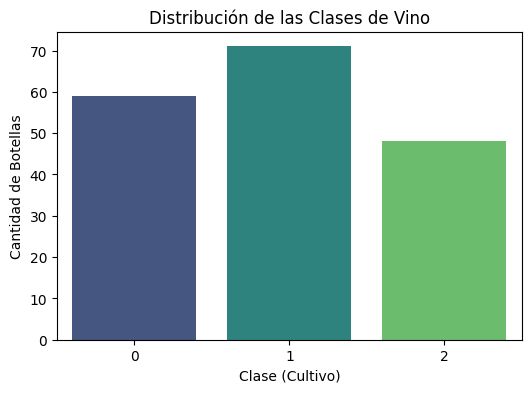

In [3]:
plt.figure(figsize=(6,4))
sns.countplot(x=y, palette='viridis')
plt.title('Distribución de las Clases de Vino')
plt.xlabel('Clase (Cultivo)')
plt.ylabel('Cantidad de Botellas')
plt.show()

---
## **Paso 2: Separación de Datos (Train/Test Split)**

Como siempre, debemos ocultarle una parte de los datos a nuestros algoritmos para poder examinarlos al final de la clase.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
print(f"Datos para entrenar (aprender): {X_train.shape[0]} botellas.")
print(f"Datos para evaluar (examen): {X_test.shape[0]} botellas.")

Datos para entrenar (aprender): 124 botellas.
Datos para evaluar (examen): 54 botellas.


---
## **Paso 3: Modelo 1 - k-Nearest Neighbors (k-NN)**

**Filosofía:** "Dime con quién andas y te diré quién eres".
El algoritmo de los $k$ vecinos más cercanos no calcula fórmulas. Cuando llega un vino nuevo, simplemente mide la distancia geométrica hacia los otros vinos. Si le decimos que $k=5$, buscará los 5 vinos más parecidos y hará una votación.

**EL PELIGRO:** Como usa distancias matemáticas, las columnas con números grandes arruinarán el cálculo frente a columnas con números pequeños.

**Demostración del problema:** Observemos el tamaño de los números en nuestros datos crudos.

In [5]:
print("Valores máximos sin escalar:")
display(X_train[['Alcohol', 'Magnesio', 'Prolina']].max())

Valores máximos sin escalar:


Alcohol       14.83
Magnesio     162.00
Prolina     1515.00
dtype: float64

¡La Prolina llega a más de 1600 mientras el Alcohol apenas a 14! k-NN creerá falsamente que la Prolina es más importante. 
**Solución Obligatoria:** Estandarizar (Escalar) los datos.

In [6]:
from sklearn.preprocessing import StandardScaler

# 1. Instanciamos el escalador
scaler = StandardScaler()

# 2. Escalamos los datos de entrenamiento y de prueba
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

print("¡Datos escalados exitosamente! Ahora todas las columnas tienen la misma importancia geométrica.")

¡Datos escalados exitosamente! Ahora todas las columnas tienen la misma importancia geométrica.


Ahora sí, entrenemos a nuestro clasificador k-NN y veamos qué tan exacto es.

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 3. Instanciar y Entrenar
knn = KNeighborsClassifier(n_neighbors=5) # Elegimos buscar a los 5 vecinos más cercanos
knn.fit(X_train_esc, y_train)

# 4. Predecir y Evaluar
pred_knn = knn.predict(X_test_esc)
acc_knn = accuracy_score(y_test, pred_knn)
print(f"Exactitud de k-NN: {acc_knn * 100:.2f}%")

Exactitud de k-NN: 94.44%


---
## **Paso 4: Modelo 2 - Árboles de Decisión**

**Filosofía:** El juego de "Adivina Quién?".
Un Árbol de Decisión no usa distancias, usa **reglas lógicas**. Buscará la columna química que mejor parta los datos en grupos puros (bajando la *Entropía* o impureza de *Gini*).

*Nota Docente: ¡Los árboles NO necesitan que escalemos los datos! A una regla If-Then no le importa el tamaño del número.*

In [8]:
from sklearn.tree import DecisionTreeClassifier

# 1. Instanciar y Entrenar
# max_depth=3 significa que solo le permitiremos hacer 3 niveles de preguntas para evitar que se "memorice" los datos (Overfitting)
arbol = DecisionTreeClassifier(max_depth=3, random_state=42) 
arbol.fit(X_train, y_train) # Usamos los datos originales (en español) sin escalar

# 2. Predecir y Evaluar
pred_arbol = arbol.predict(X_test)
acc_arbol = accuracy_score(y_test, pred_arbol)
print(f"Exactitud del Árbol de Decisión: {acc_arbol * 100:.2f}%")

Exactitud del Árbol de Decisión: 96.30%


**Visualización del Árbol:**
La mayor ventaja de un árbol es que podemos imprimir su "cerebro" y leer exactamente qué decisiones tomó. Fíjese cómo las columnas traducidas al español aparecen directamente en el gráfico.

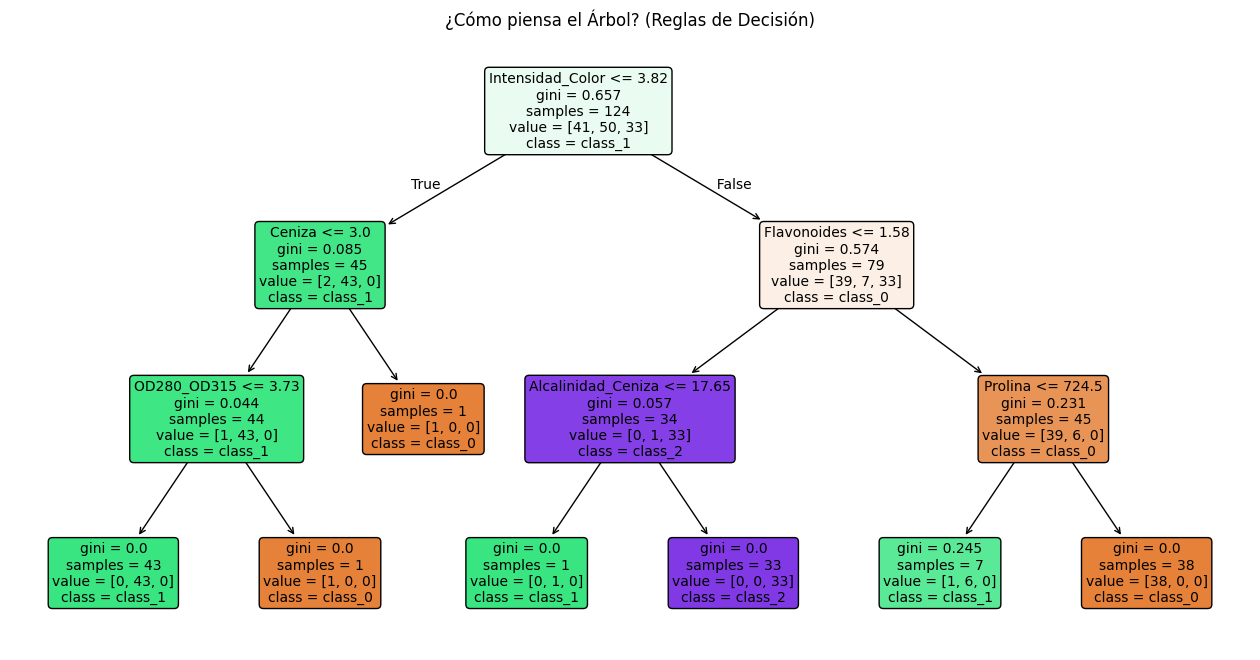

In [9]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))
plot_tree(arbol, 
          feature_names=X.columns, # Usamos nuestras nuevas columnas en español
          class_names=datos_vino.target_names, 
          filled=True, 
          rounded=True,
          fontsize=10)
plt.title('¿Cómo piensa el Árbol? (Reglas de Decisión)')
plt.show()

---
## **Paso 5: Modelo 3 - Naive Bayes**

**Filosofía:** Probabilidad Pura (Teorema de Bayes).
Se llama "Ingenuo" (*Naive*) porque asume que el nivel de Alcohol no tiene relación matemática con el Magnesio. En la realidad esto es falso, pero asumir esa ingenuidad hace que el cálculo de probabilidades sea **extremadamente rápido**.

In [10]:
from sklearn.naive_bayes import GaussianNB

# 1. Instanciar y Entrenar
bayes = GaussianNB()
bayes.fit(X_train, y_train)

# 2. Predecir y Evaluar
pred_bayes = bayes.predict(X_test)
acc_bayes = accuracy_score(y_test, pred_bayes)
print(f"Exactitud de Naive Bayes: {acc_bayes * 100:.2f}%")

Exactitud de Naive Bayes: 100.00%


---
## **Paso 6: Comparación de Fronteras de Decisión (Visualización de los Datos Reales)**

Para entender verdaderamente cómo funciona cada algoritmo (y para que sea fácil de enseñar a la clase), **reduciremos nuestro dataset a solo 2 columnas** (`Alcohol` y `Flavonoides`) para poder graficarlo en un plano de 2 dimensiones (X e Y).

Esto nos permitirá ver visualmente cómo cada algoritmo "corta" (Frontera de Decisión) la gráfica para clasificar los vinos.

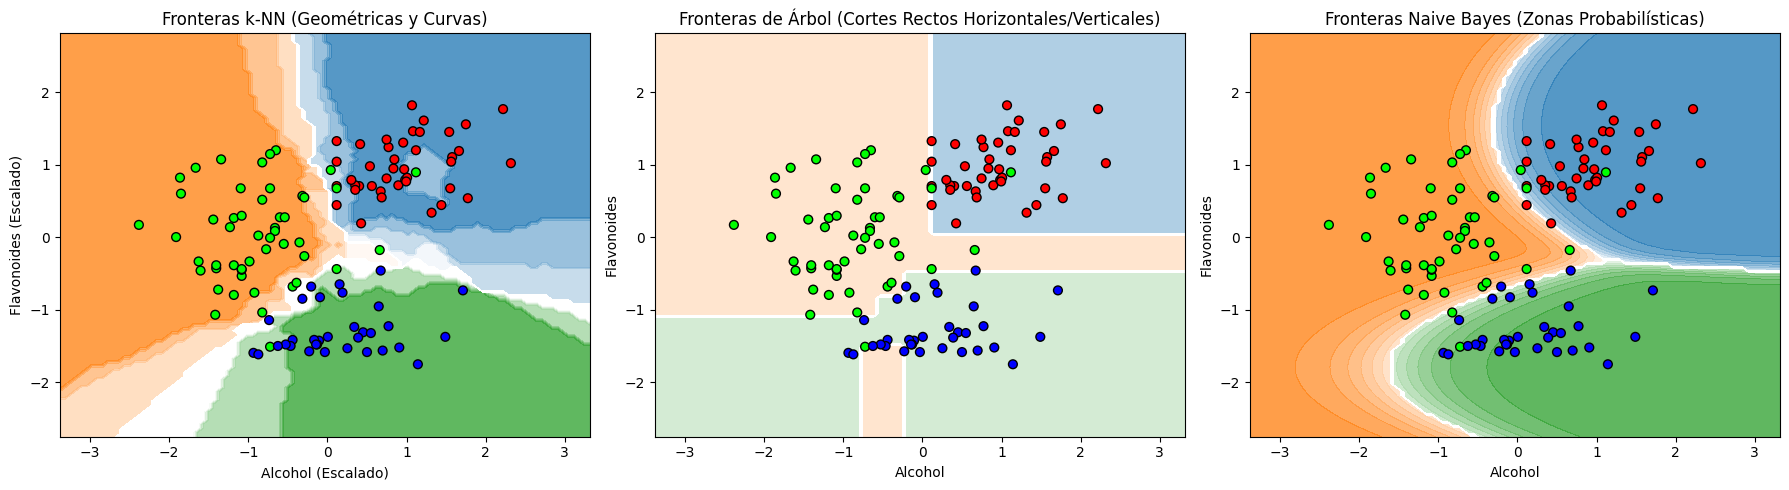

In [11]:
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

# Para poder graficar en 2D, elegimos solo 2 características.
X_2D = X_train[['Alcohol', 'Flavonoides']]

# k-NN sufre si no lo escalamos, así que escalamos estas 2 columnas
scaler_2d = StandardScaler()
X_2D_esc = scaler_2d.fit_transform(X_2D)

# Entrenamos 3 modelos "miniaturas" que solo ven estas 2 columnas
knn_2d = KNeighborsClassifier(n_neighbors=5).fit(X_2D_esc, y_train)
arbol_2d = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_2D_esc, y_train)
bayes_2d = GaussianNB().fit(X_2D_esc, y_train)

# Configuración del gráfico (3 paneles)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

# --- 1. Panel de k-NN ---
DecisionBoundaryDisplay.from_estimator(knn_2d, X_2D_esc, cmap=cmap_light, ax=ax1, alpha=0.8)
ax1.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax1.set_title("Fronteras k-NN (Geométricas y Curvas)")
ax1.set_xlabel('Alcohol (Escalado)')
ax1.set_ylabel('Flavonoides (Escalado)')

# --- 2. Panel de Árbol de Decisión ---
DecisionBoundaryDisplay.from_estimator(arbol_2d, X_2D_esc, cmap=cmap_light, ax=ax2, alpha=0.8)
ax2.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax2.set_title("Fronteras de Árbol (Cortes Rectos Horizontales/Verticales)")
ax2.set_xlabel('Alcohol')
ax2.set_ylabel('Flavonoides')

# --- 3. Panel de Naive Bayes ---
DecisionBoundaryDisplay.from_estimator(bayes_2d, X_2D_esc, cmap=cmap_light, ax=ax3, alpha=0.8)
ax3.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax3.set_title("Fronteras Naive Bayes (Zonas Probabilísticas)")
ax3.set_xlabel('Alcohol')
ax3.set_ylabel('Flavonoides')

plt.tight_layout()
plt.show()

Observe las gráficas de arriba junto a sus alumnos:
* **k-NN** genera áreas curvas de decisión como si trazara contornos geográficos intentando rodear a los grupitos.
* **Árbol de Decisión** JAMÁS genera curvas. Todo son cortes perfectamente rectos horizontales y verticales, porque son reglas de "Mayor que" y "Menor que".
* **Naive Bayes** genera zonas amplias y suavizadas dictadas por las campanas de distribución probabilística.

---
## **Paso 7: Comparación de Desempeño y Conclusión de Taller**

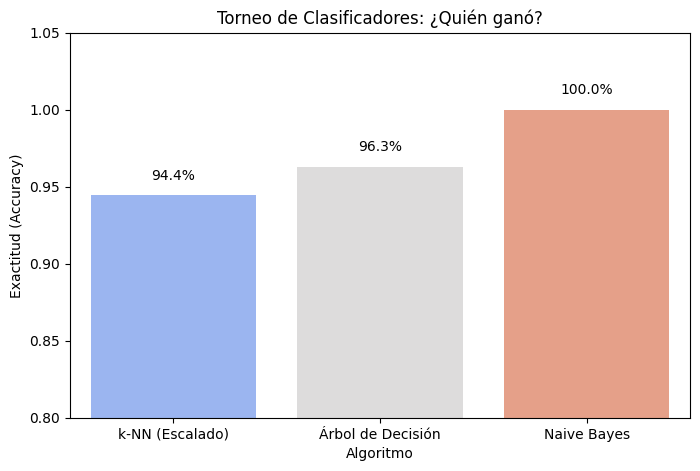

In [12]:
# Crear un DataFrame con los resultados
resultados = pd.DataFrame({
    'Algoritmo': ['k-NN (Escalado)', 'Árbol de Decisión', 'Naive Bayes'],
    'Exactitud (Accuracy)': [acc_knn, acc_arbol, acc_bayes]
})

# Graficar comparativa
plt.figure(figsize=(8,5))
sns.barplot(x='Algoritmo', y='Exactitud (Accuracy)', data=resultados, palette='coolwarm')
plt.title('Torneo de Clasificadores: ¿Quién ganó?')
plt.ylim(0.8, 1.05) # Enfocar el gráfico en la parte alta para notar las diferencias

# Agregar etiquetas de porcentaje en las barras
for index, row in resultados.iterrows():
    plt.text(index, row['Exactitud (Accuracy)'] + 0.01, f"{row['Exactitud (Accuracy)']*100:.1f}%", color='black', ha="center")

plt.show()

### **Conclusión del Docente:**
En este dataset en particular, los resultados pueden ser muy parejos. Sin embargo, en el mundo real:
* Si el cliente necesita saber **POR QUÉ** se tomó una decisión (ej. Auditoría Médica o Legal), el **Árbol de Decisión** es el único que da explicaciones visuales.
* Si el dataset fuera de 5 millones de correos electrónicos (texto gigante), **k-NN** colapsaría y **Naive Bayes** lo resolvería en segundos.
* Si las fronteras de separación son muy complejas y curvas, **k-NN** suele adaptarse maravillosamente.

---
## **Paso 7 (Tarea): Mapa de Calor, Tercera Característica y Fronteras de Decisión**

**Objetivo de la tarea:**
1. Hacer un **mapa de calor de correlaciones** del dataset de vinos para identificar la **tercera característica más representativa**.
2. Graficar esa característica en **pares contra `Alcohol` y `Flavonoides`**.
3. Evaluar **k-NN, Árbol de Decisión y Naive Bayes** sobre esos pares y determinar cuál ofrece la **representación gráfica de clasificación más clara**.

### 7.1 Mapa de calor de correlaciones
Para saber qué tan "representativa" es cada característica, la correlacionamos contra la clase de vino. Por eso agrego la columna `Clase_de_Vino` al DataFrame antes de calcular la matriz.

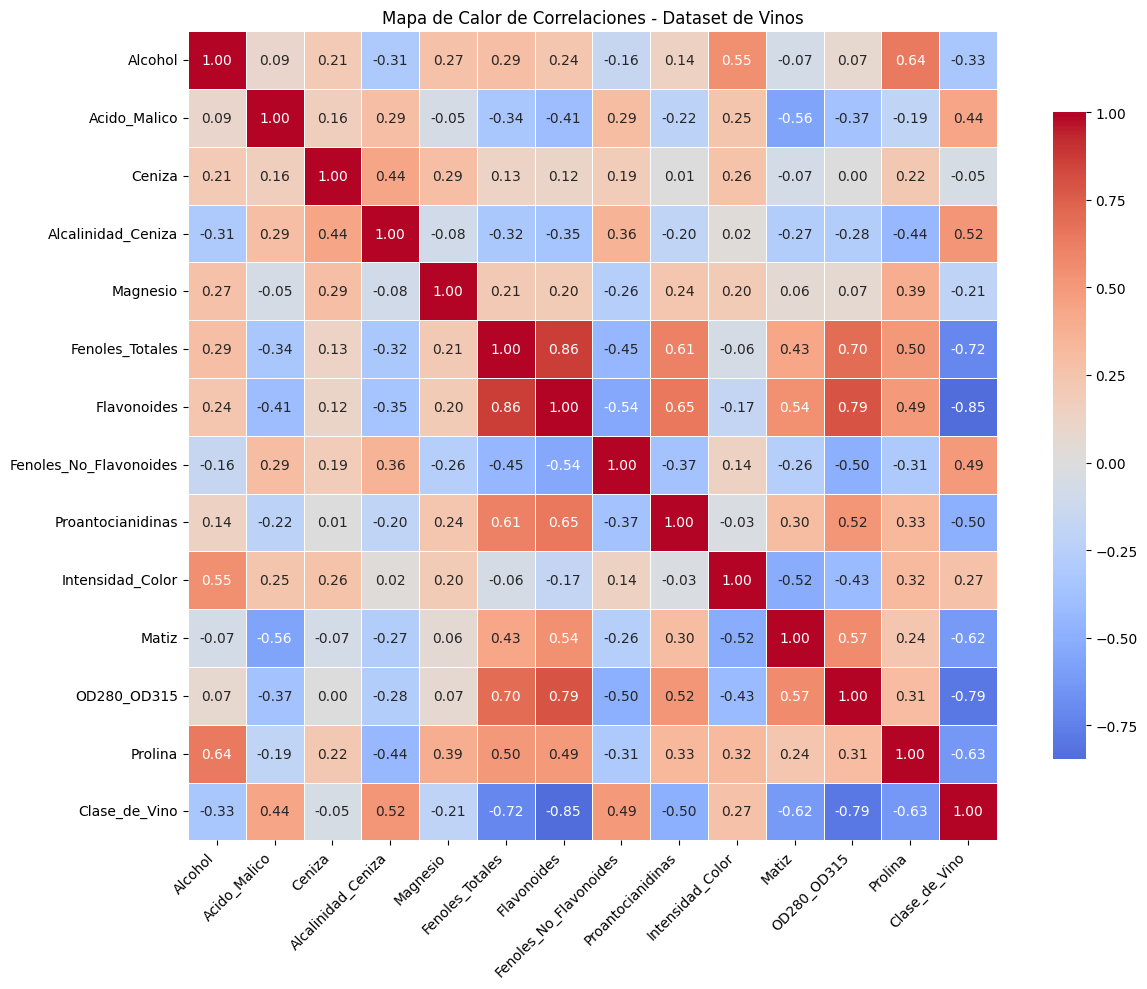

In [13]:
# Unimos las características con la clase para poder correlacionarlas con lo que queremos predecir
df_corr = X.copy()
df_corr['Clase_de_Vino'] = y

matriz_corr = df_corr.corr()

plt.figure(figsize=(13, 10))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, square=True, cbar_kws={'shrink': 0.8})
plt.title('Mapa de Calor de Correlaciones - Dataset de Vinos')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 7.2 ¿Cuál es la tercera característica más representativa?
Ordeno las características por el **valor absoluto** de su correlación con la clase (no importa si la correlación es positiva o negativa, lo que importa es qué tan fuerte es la relación).

,|Correlación| con la clase
Flavonoides,0.847498
OD280_OD315,0.788230
Fenoles_Totales,0.719163
Prolina,0.633717
Matiz,0.617369
Alcalinidad_Ceniza,0.517859
Proantocianidinas,0.499130
Fenoles_No_Flavonoides,0.489109
Acido_Malico,0.437776
Alcohol,0.328222


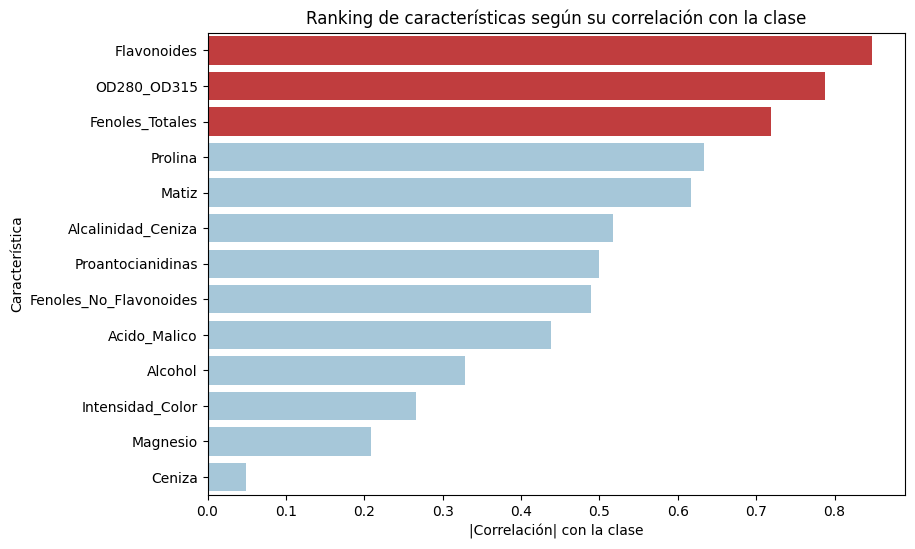

Top 3 del ranking: ['Flavonoides', 'OD280_OD315', 'Fenoles_Totales']
Tercera característica más representativa: Fenoles_Totales (|r| = 0.719)


In [14]:
# Correlación de cada característica contra la clase (sin contar la clase contra sí misma)
corr_clase = matriz_corr['Clase_de_Vino'].drop('Clase_de_Vino')
ranking = corr_clase.abs().sort_values(ascending=False)

display(ranking.to_frame('|Correlación| con la clase'))

plt.figure(figsize=(9, 6))
colores = ['#d62728' if i < 3 else '#9ecae1' for i in range(len(ranking))]
sns.barplot(x=ranking.values, y=ranking.index, palette=colores)
plt.title('Ranking de características según su correlación con la clase')
plt.xlabel('|Correlación| con la clase')
plt.ylabel('Característica')
plt.show()

# La tercera del ranking
tercera = ranking.index[2]
print(f"Top 3 del ranking: {list(ranking.index[:3])}")
print(f"Tercera característica más representativa: {tercera} (|r| = {ranking.iloc[2]:.3f})")

In [15]:
# Reviso qué tan relacionada está la tercera característica con Alcohol y Flavonoides
print(f"Correlación de {tercera} con Alcohol:     {matriz_corr.loc[tercera, 'Alcohol']:.3f}")
print(f"Correlación de {tercera} con Flavonoides: {matriz_corr.loc[tercera, 'Flavonoides']:.3f}")

Correlación de Fenoles_Totales con Alcohol:     0.289
Correlación de Fenoles_Totales con Flavonoides: 0.865


### 7.3 Gráfica de pares: tercera característica vs. Alcohol y vs. Flavonoides
Ahora grafico la tercera característica contra `Alcohol` y contra `Flavonoides`, coloreando cada punto por su clase de vino. Con esto veo a simple vista qué tan separadas quedan las 3 clases en cada par.

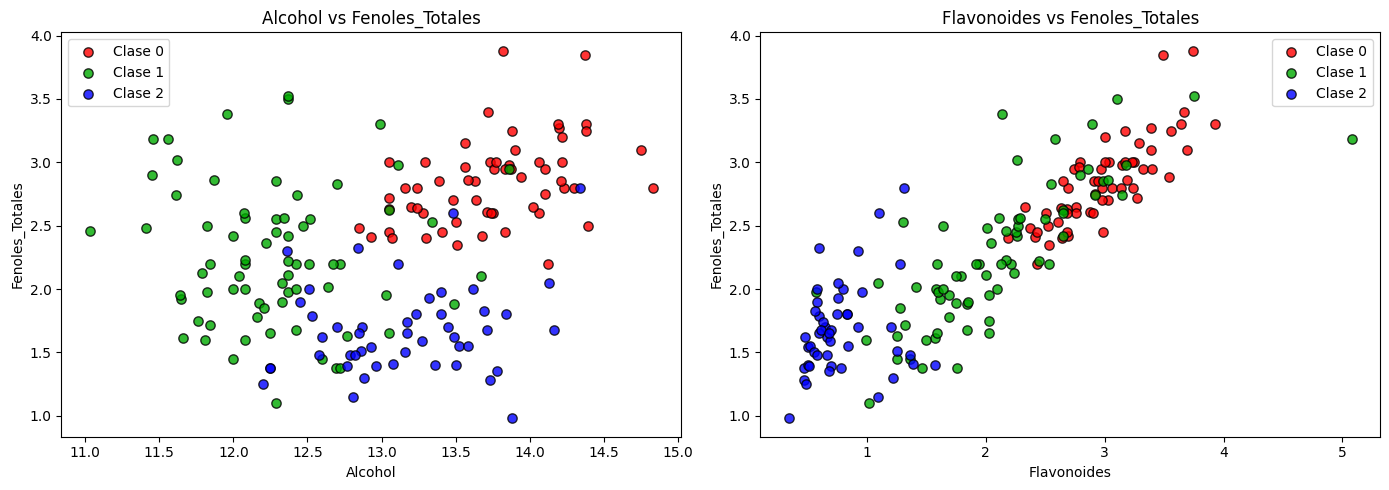

In [16]:
colores_clase = {0: '#FF0000', 1: '#00AA00', 2: '#0000FF'}
nombres_clase = {0: 'Clase 0', 1: 'Clase 1', 2: 'Clase 2'}

pares = [('Alcohol', tercera), ('Flavonoides', tercera)]

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for eje, (col_x, col_y) in zip(ejes, pares):
    for clase in [0, 1, 2]:
        mascara = (y == clase)
        eje.scatter(X.loc[mascara, col_x], X.loc[mascara, col_y],
                    c=colores_clase[clase], label=nombres_clase[clase],
                    edgecolor='k', s=45, alpha=0.8)
    eje.set_xlabel(col_x)
    eje.set_ylabel(col_y)
    eje.set_title(f'{col_x} vs {col_y}')
    eje.legend()
plt.tight_layout()
plt.show()

### 7.4 Evaluación de los 3 modelos sobre cada par de características
Para cada par (`Alcohol` vs tercera característica y `Flavonoides` vs tercera característica) entreno los tres modelos con **solo 2 columnas** y dibujo sus fronteras de decisión, igual que en el Paso 6.

Mantengo las mismas condiciones que en el resto del taller:
- Mismo `train_test_split` del Paso 2 (70% / 30%, `random_state=42`).
- Datos **escalados** con `StandardScaler` (necesario para k-NN y de paso se usa igual en los tres para poder compararlos).
- k-NN con `k=5`, Árbol con `max_depth=4` (igual que en el Paso 6) y `GaussianNB`.

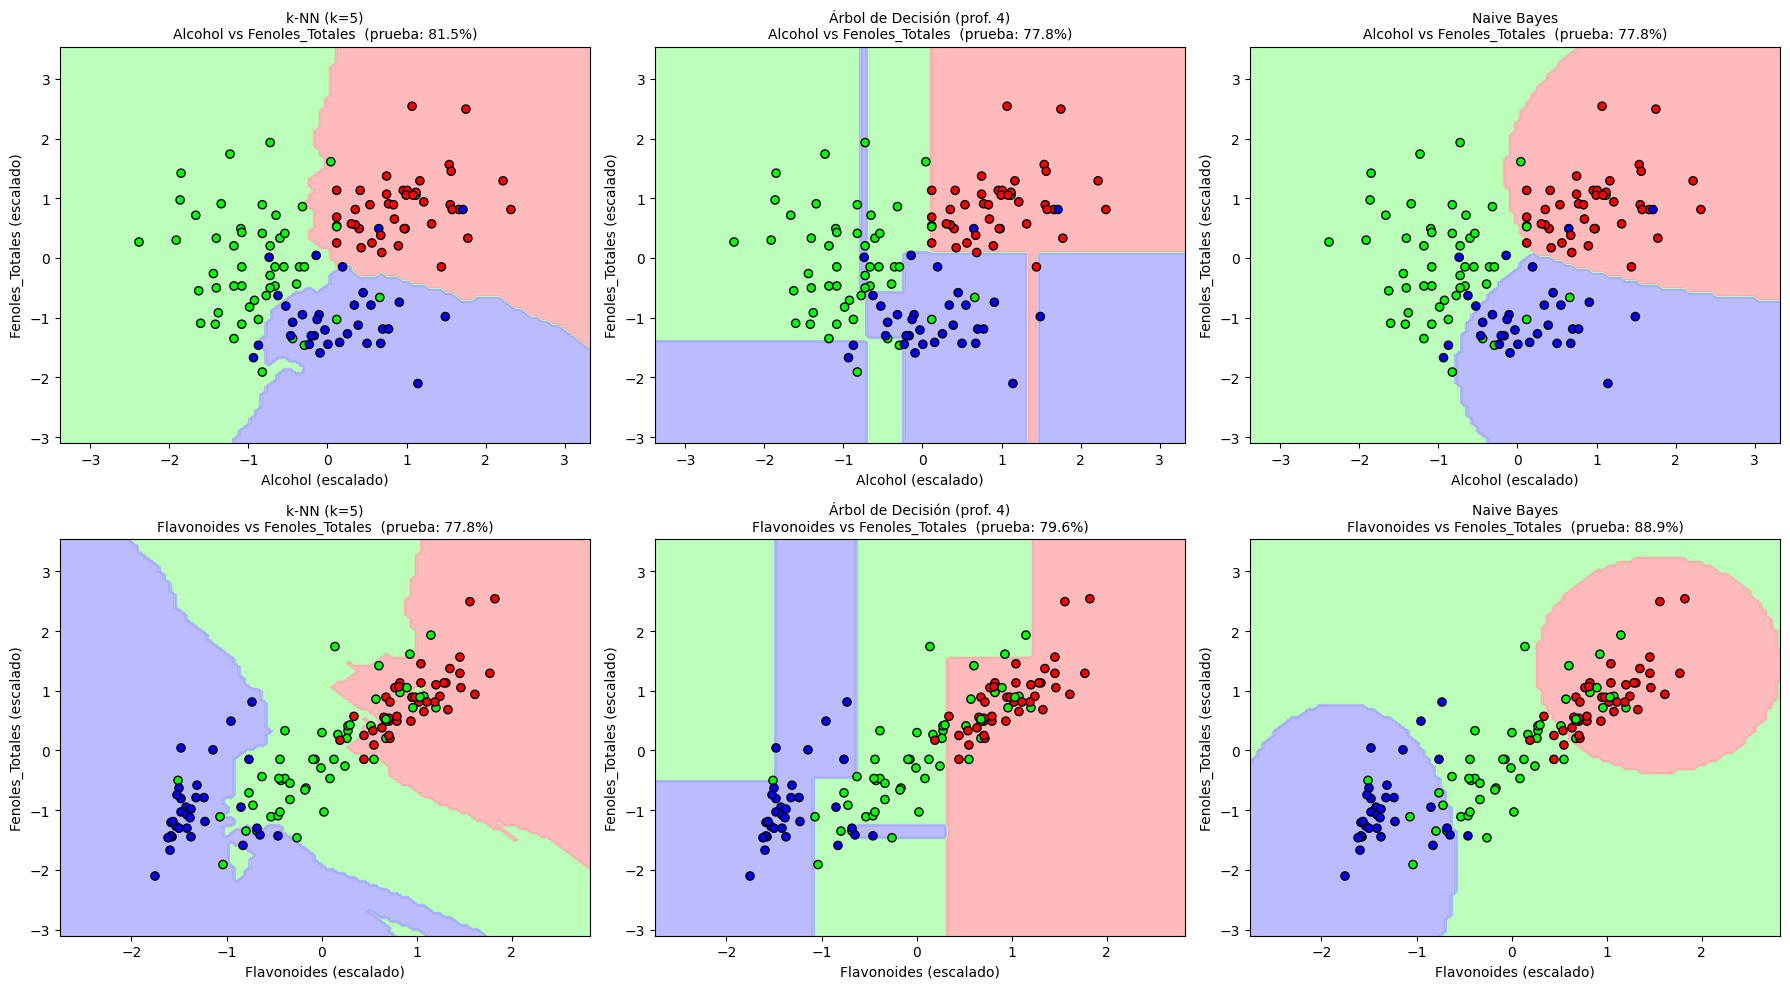

In [17]:
def entrenar_y_graficar(par, fila_ejes):
    """Entrena los 3 modelos con un par de columnas, dibuja sus fronteras
    y devuelve las exactitudes (entrenamiento y prueba)."""
    col_a, col_b = par

    # Escalamos solo estas 2 columnas (ajustando con entrenamiento nada más)
    esc = StandardScaler()
    Xtr = esc.fit_transform(X_train[[col_a, col_b]])
    Xte = esc.transform(X_test[[col_a, col_b]])

    modelos = {
        'k-NN (k=5)': KNeighborsClassifier(n_neighbors=5),
        'Árbol de Decisión (prof. 4)': DecisionTreeClassifier(max_depth=4, random_state=42),
        'Naive Bayes': GaussianNB()
    }

    exactitudes = []
    for eje, (nombre, modelo) in zip(fila_ejes, modelos.items()):
        modelo.fit(Xtr, y_train)
        acc_tr = accuracy_score(y_train, modelo.predict(Xtr))
        acc_te = accuracy_score(y_test, modelo.predict(Xte))
        exactitudes.append({'Par': f'{col_a} vs {col_b}', 'Modelo': nombre,
                            'Exactitud entrenamiento': acc_tr, 'Exactitud prueba': acc_te})

        DecisionBoundaryDisplay.from_estimator(modelo, Xtr, response_method='predict', cmap=cmap_light, ax=eje, alpha=0.8)
        eje.scatter(Xtr[:, 0], Xtr[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=35)
        eje.set_title(f'{nombre}\n{col_a} vs {col_b}  (prueba: {acc_te*100:.1f}%)', fontsize=10)
        eje.set_xlabel(f'{col_a} (escalado)')
        eje.set_ylabel(f'{col_b} (escalado)')
    return exactitudes


# cmap_light y cmap_bold vienen del Paso 6; por si acaso los redefino
from matplotlib.colors import ListedColormap
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

fig, ejes = plt.subplots(2, 3, figsize=(18, 10))
res_1 = entrenar_y_graficar(('Alcohol', tercera), ejes[0])
res_2 = entrenar_y_graficar(('Flavonoides', tercera), ejes[1])
plt.tight_layout()
plt.show()

,Par,Modelo,Exactitud entrenamiento,Exactitud prueba
0,Alcohol vs Fenoles_Totales,k-NN (k=5),87.90,81.48
1,Alcohol vs Fenoles_Totales,Árbol de Decisión (prof. 4),94.35,77.78
2,Alcohol vs Fenoles_Totales,Naive Bayes,87.10,77.78
3,Flavonoides vs Fenoles_Totales,k-NN (k=5),79.84,77.78
4,Flavonoides vs Fenoles_Totales,Árbol de Decisión (prof. 4),85.48,79.63
5,Flavonoides vs Fenoles_Totales,Naive Bayes,75.81,88.89


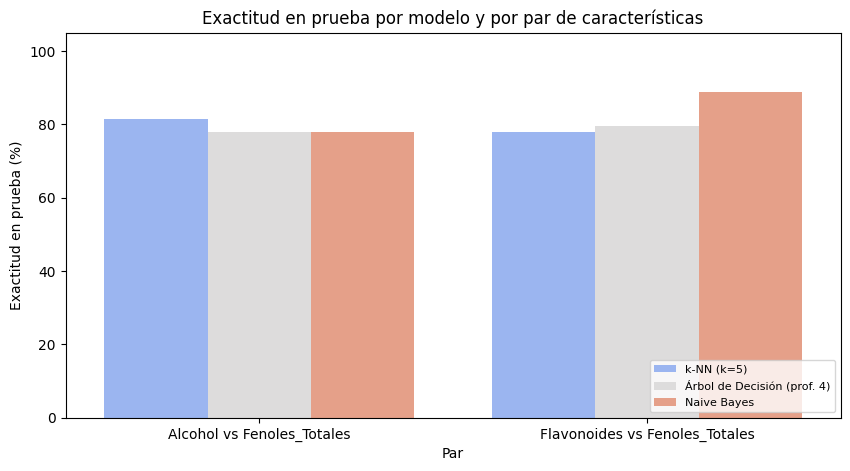

In [18]:
# Tabla resumen con las exactitudes de cada modelo en cada par
tabla = pd.DataFrame(res_1 + res_2)
tabla['Exactitud entrenamiento'] = (tabla['Exactitud entrenamiento'] * 100).round(2)
tabla['Exactitud prueba'] = (tabla['Exactitud prueba'] * 100).round(2)
display(tabla)

# Gráfica comparativa de la exactitud en prueba
plt.figure(figsize=(10, 5))
sns.barplot(data=tabla, x='Par', y='Exactitud prueba', hue='Modelo', palette='coolwarm')
plt.title('Exactitud en prueba por modelo y por par de características')
plt.ylabel('Exactitud en prueba (%)')
plt.ylim(0, 105)
plt.legend(loc='lower right', fontsize=8)
plt.show()

### 7.5 Conclusiones de la tarea

**Tercera característica más representativa.** En el mapa de calor y en el ranking, las características que más se correlacionan con la clase de vino son `Flavonoides` (|r| = 0.85), `OD280_OD315` (|r| = 0.79) y **`Fenoles_Totales` (|r| = 0.72)**, así que esta última es la tercera. Algo importante que noté es que `Fenoles_Totales` está muy correlacionada con `Flavonoides` (r = 0.865), o sea que casi miden lo mismo, mientras que con `Alcohol` la correlación es baja (r = 0.289), por lo que ahí aporta información más distinta.

**Lo que se ve en las gráficas de pares (7.3).**
- En **Alcohol vs Fenoles_Totales** las tres clases forman tres grupos bastante separados: la clase 0 (rojo) arriba a la derecha, la clase 1 (verde) a la izquierda y la clase 2 (azul) abajo. Solo se mezclan unos pocos puntos en el centro.
- En **Flavonoides vs Fenoles_Totales** todos los puntos se acomodan a lo largo de una diagonal (por la correlación tan alta), y las clases 0 y 1 se montan una sobre otra en la parte media. Este par se ve más difícil de separar.

**Comparación de los modelos (7.4).**

| Par | k-NN (prueba) | Árbol (prueba) | Naive Bayes (prueba) |
|---|---|---|---|
| Alcohol vs Fenoles_Totales | 81.48% | 77.78% | 77.78% |
| Flavonoides vs Fenoles_Totales | 77.78% | 79.63% | 88.89% |

- **k-NN:** con el par de Alcohol sí logra la mejor exactitud (81.48%), pero sus fronteras se ven irregulares y con "islitas" pequeñas alrededor de puntos sueltos. En el par con Flavonoides se vuelve todavía más desordenado, porque trata de rodear cada punto de la zona donde se mezclan las clases.
- **Árbol de Decisión:** es el que se ve más fragmentado, con rectángulos y tiras angostas que aparecen en zonas donde ni siquiera hay datos. Además tiene la mayor diferencia entre entrenamiento y prueba (94.35% contra 77.78% en el par de Alcohol), lo que indica que se está memorizando los datos (sobreajuste).
- **Naive Bayes:** dibuja regiones suaves y compactas (curvas tipo elipse), una por clase, que cubren de forma continua las zonas donde están los grupos. Es la gráfica que se entiende más rápido de un vistazo y en el par de Flavonoides alcanza la mejor exactitud de todas (88.89%).

**Respuesta final.** El modelo que ofrece la **representación gráfica de clasificación más clara es Naive Bayes**, porque sus fronteras son suaves, no tienen fragmentos ni islas y se nota fácilmente qué zona le corresponde a cada clase. Esto tiene sentido porque Naive Bayes asume que cada clase tiene forma de campana (distribución normal), y en estos pares los grupos se parecen bastante a eso. El **par más claro de interpretar** visualmente es **Alcohol vs Fenoles_Totales**, porque ahí las clases sí quedan separadas en grupos.

**Observaciones finales.**
- Con solo 54 datos de prueba, cada dato equivale a casi 1.85 puntos porcentuales, así que las diferencias de exactitud entre modelos son pequeñas y hay que tomarlas con cuidado. La claridad de la gráfica es el criterio principal de esta tarea.
- Elegir una característica muy correlacionada con otra que ya usamos (como `Fenoles_Totales` con `Flavonoides`) no agrega mucha información nueva, por eso las gráficas con ese par se ven más encimadas que las de Alcohol.
- Los tres modelos usando solo 2 columnas rinden peor que usando las 13 características, como se vio en los pasos anteriores del taller, pero el trabajo en 2D es lo que nos permite *ver* cómo piensa cada algoritmo.
